# Word Embedding Bias, One Number at a Time: Companion Notebook

This notebook follows **`embedding_bias_math_guide.pdf` exactly**: same parts, same order, same toy numbers, same six-part pattern in every section:

1. The question it answers
2. Everyday picture
3. The formula (every symbol explained)
4. Work it out (the code prints each arithmetic line, just like the guide)
5. What the answer means
6. Common mix-up

Every result is checked against the number printed in the guide. A line ending in `✓ matches guide` means the notebook and the PDF agree.

**How to use it:** run all cells once and read along with the PDF. Then change a number in the toy world cell, re-run, and watch which results move. (After you change numbers, the `✓` checks will start failing on purpose; that's expected.)

**Honesty note:** the vectors are invented for teaching. Real embeddings have 300 dimensions, and no single dimension cleanly means "caregiving." The formulas are the papers' real formulas.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=3, suppress=True)

def check(value, expected, tol=0.006):
    ok = abs(value - expected) <= tol
    return "✓ matches guide" if ok else f"✗ guide says {expected}"

def fmt(x, d=2):
    return f"{x:.{d}f}".replace("-", "−")

def sgn(x, d=3, lead=True):
    # Signed term: "−0.078" or "+ 0.922" style, using a true minus sign.
    if lead:
        return fmt(x, d)
    return f"{'+' if x >= 0 else '−'} {abs(x):.{d}f}"

def show_dot(name_a, a, name_b, b, d_terms=4, d_total=2, expected=None):
    # Print a dot product the way the guide writes it.
    a, b = np.asarray(a, float), np.asarray(b, float)
    terms = a * b
    print(f"{name_a} · {name_b}")
    print("= " + " + ".join(f"({fmt(x)})({fmt(y)})" for x, y in zip(a, b)))
    print("= " + " + ".join(fmt(t, d_terms) for t in terms))
    total = terms.sum()
    line = f"= {fmt(total, d_total)}"
    if expected is not None:
        line += "     " + check(total, expected)
    print(line + "\n")
    return total

# Part 0. The four tools you need

Almost everything in both papers is built from four small ideas. We practice each one with just **two** numbers first.

### Tool 1: A vector is a list of dial settings
Picture a mixing board with sliders. A word's vector is where each slider sits. With two sliders, $a = (3, 4)$ means slider one at 3, slider two at 4.

### Tool 2: The dot product (multiply matching sliders, then add)
$$a \cdot b = a_1 b_1 + a_2 b_2 + \dots$$

In [2]:
a = np.array([3, 4]); b = np.array([2, 1])
show_dot("a", a, "b", b, d_terms=0, d_total=0, expected=10)

a · b
= (3.00)(2.00) + (4.00)(1.00)
= 6 + 4
= 10     ✓ matches guide



np.float64(10.0)

### Tool 3: Length (how long the arrow is)
$$\lVert a \rVert = \sqrt{a \cdot a}$$
This is the Pythagorean theorem.

In [3]:
length = np.sqrt(a @ a)
print(f"‖a‖ = √(a · a) = √(3 × 3 + 4 × 4) = √(9 + 16) = √25 = {length:.0f}     {check(length, 5)}")

‖a‖ = √(a · a) = √(3 × 3 + 4 × 4) = √(9 + 16) = √25 = 5     ✓ matches guide


### Tool 4: Unit vector (shrink the arrow to length 1)
$$\hat a = a \div \lVert a \rVert$$
Divide every slider by the length. The arrow keeps its direction but now has length exactly 1.

In [4]:
a_hat = a / length
print(f"â = a ÷ ‖a‖ = (3 ÷ 5, 4 ÷ 5) = ({a_hat[0]:.1f}, {a_hat[1]:.1f})")
print(f"check: 0.6² + 0.8² = 0.36 + 0.64 = {a_hat @ a_hat:.2f}  ✓")

â = a ÷ ‖a‖ = (3 ÷ 5, 4 ÷ 5) = (0.6, 0.8)
check: 0.6² + 0.8² = 0.36 + 0.64 = 1.00  ✓


**Why bother with length 1?** Once two arrows both have length 1, their dot product tells you *only* how much they point the same way. That number is the **cosine**, always between −1 and 1. The three landmark values:

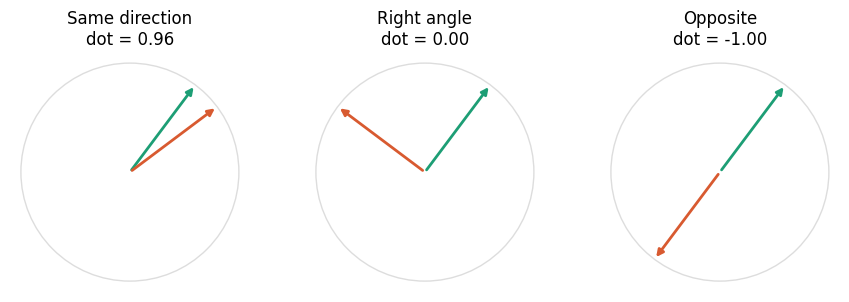

In [5]:
cases = [((0.6, 0.8), (0.8, 0.6), "Same direction"),
         ((0.6, 0.8), (-0.8, 0.6), "Right angle"),
         ((0.6, 0.8), (-0.6, -0.8), "Opposite")]
fig, axs = plt.subplots(1, 3, figsize=(9, 3))
for ax, (u, v, label) in zip(axs, cases):
    d = np.dot(u, v)
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="#ddd"))
    ax.annotate("", xy=u, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color="#1D9E75", lw=2))
    ax.annotate("", xy=v, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color="#D85A30", lw=2))
    ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(f"{label}\ndot = {d:.2f}")
plt.tight_layout(); plt.show()

# The toy world

Each word has three sliders: **gender** (positive leans *she*, negative leans *he*), **caregiving**, and **expertise**. Every vector already has length 1, so we can skip Tool 4 from here on.

The **gender direction** is $g = (1, 0, 0)$: the first slider by itself. (In the real paper, finding $g$ takes work; see Part 9.)

In [6]:
# ---- Edit these numbers to experiment (the ✓ checks will then fail on purpose) ----
E = {
    "nurse":       np.array([ 0.36, 0.48, 0.80]),
    "doctor":      np.array([-0.48, 0.36, 0.80]),
    "babysit":     np.array([ 0.60, 0.80, 0.00]),
    "grandmother": np.array([ 0.60, 0.64, 0.48]),
    "grandfather": np.array([-0.48, 0.60, 0.64]),
}
g = np.array([1.0, 0.0, 0.0])
# ------------------------------------------------------------------------------------

print(f"{'Word':12s} {'Gender':>8s} {'Caregiving':>11s} {'Expertise':>10s}")
for w, v in E.items():
    print(f"{w:12s} {fmt(v[0]):>8s} {fmt(v[1]):>11s} {fmt(v[2]):>10s}")

n = E["nurse"]
print(f"\nQuick length check, nurse: 0.36² + 0.48² + 0.80² = "
      f"{n[0]**2:.4f} + {n[1]**2:.4f} + {n[2]**2:.4f} = {n @ n:.2f}  ✓")

Word           Gender  Caregiving  Expertise
nurse            0.36        0.48       0.80
doctor          −0.48        0.36       0.80
babysit          0.60        0.80       0.00
grandmother      0.60        0.64       0.48
grandfather     −0.48        0.60       0.64

Quick length check, nurse: 0.36² + 0.48² + 0.80² = 0.1296 + 0.2304 + 0.6400 = 1.00  ✓


# Part 1. Cosine similarity

**The question it answers:** How similar are two words?

**Everyday picture:** Two people choosing pizza toppings. If they pick mostly the same toppings in the same amounts, their orders are similar. The dot product scores that overlap.

**The formula**
$$\cos(u, v) = u \cdot v \qquad \text{(when both have length 1)}$$
$u, v$ = two word vectors. $u \cdot v$ = multiply matching sliders, then add.

**Work it out**

In [7]:
show_dot("nurse", E["nurse"], "doctor", E["doctor"], expected=0.64)
show_dot("nurse", E["nurse"], "babysit", E["babysit"], d_terms=3, expected=0.60)
show_dot("doctor", E["doctor"], "babysit", E["babysit"], d_terms=3, expected=0.00);

nurse · doctor
= (0.36)(−0.48) + (0.48)(0.36) + (0.80)(0.80)
= −0.1728 + 0.1728 + 0.6400
= 0.64     ✓ matches guide

nurse · babysit
= (0.36)(0.60) + (0.48)(0.80) + (0.80)(0.00)
= 0.216 + 0.384 + 0.000
= 0.60     ✓ matches guide

doctor · babysit
= (−0.48)(0.60) + (0.36)(0.80) + (0.80)(0.00)
= −0.288 + 0.288 + 0.000
= 0.00     ✓ matches guide



**What the answer means:** Nurse and doctor are fairly similar (0.64). Doctor and babysit are unrelated (0.00). In the nurse · doctor work, the gender term is **negative** (−0.1728): one leans *she*, the other leans *he*, so gender pushes them apart. Keep that in mind for Part 4.

**Common mix-up:** Cosine is not a percentage. 0.64 does not mean "64% the same word." It is a score on a −1 to 1 scale.

# Part 2. Projection (the shadow)

**The question it answers:** How far does a word lean toward *she* or *he*?

**Everyday picture:** Hold a stick at an angle under a lamp. Its shadow on the floor shows how far it leans sideways. The gender line is the floor; projection is the shadow's length.

**The formula**
$$p(w) = w \cdot g$$
$w$ = a word vector. $g$ = the gender direction, here $(1, 0, 0)$.

**Work it out**

In [8]:
expected = {"nurse": 0.36, "doctor": -0.48, "babysit": 0.60}
neutral = list(expected)
proj = {}
for w in neutral:
    proj[w] = E[w] @ g
    print(f"{w:8s} · g = ({fmt(E[w][0])})(1) + ({fmt(E[w][1])})(0) + ({fmt(E[w][2])})(0) = "
          f"{'+' if proj[w] >= 0 else ''}{fmt(proj[w])}     {check(proj[w], expected[w])}")

nurse    · g = (0.36)(1) + (0.48)(0) + (0.80)(0) = +0.36     ✓ matches guide
doctor   · g = (−0.48)(1) + (0.36)(0) + (0.80)(0) = −0.48     ✓ matches guide
babysit  · g = (0.60)(1) + (0.80)(0) + (0.00)(0) = +0.60     ✓ matches guide


Because $g$ is $(1, 0, 0)$, the dot product just picks out the gender slider. That's a toy shortcut; in the real embedding, $g$ mixes all 300 sliders.

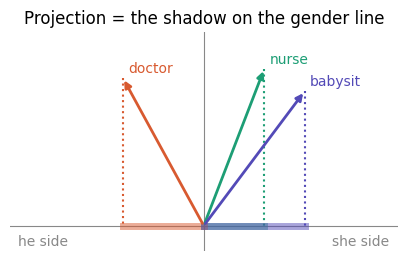

In [9]:
colors = {"nurse": "#1D9E75", "doctor": "#D85A30", "babysit": "#534AB7"}
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.axhline(0, color="#888", lw=0.8); ax.axvline(0, color="#888", lw=0.8)
for w in neutral:
    x = proj[w]; y = np.sqrt(1 - x**2)
    ax.annotate("", xy=(x, y), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=colors[w], lw=2))
    ax.plot([x, x], [y, 0], ls=":", color=colors[w]); ax.plot([0, x], [0, 0], color=colors[w], lw=5, alpha=.5)
    ax.text(x + 0.03, y + 0.03, w, color=colors[w])
ax.text(-1.1, -0.12, "he side", color="#888"); ax.text(1.1, -0.12, "she side", ha="right", color="#888")
ax.set_xlim(-1.15, 1.15); ax.set_ylim(-0.15, 1.15); ax.set_aspect("equal"); ax.axis("off")
ax.set_title("Projection = the shadow on the gender line"); plt.show()

**What the answer means:** Positive = leans *she*; negative = leans *he*; bigger number = stronger lean. Sorting every occupation by this number is how Bolukbasi et al. built their Figure 1.

**Common mix-up:** A lean is not automatically bias. *Grandmother* **should** lean *she*. Projection only signals bias for words that should be gender-neutral, like *nurse*.

# Part 3. DirectBias

**The question it answers:** Overall, how much do gender-neutral words lean?

**Everyday picture:** Checking if a floor is level by rolling marbles. Measure how far each marble rolls, ignore which way, and average. A level floor scores 0.

**The formula**
$$\text{DirectBias}_c = \frac{1}{|N|} \sum_{w \in N} \lvert w \cdot g \rvert^{c}$$
$|\dots|$ = absolute value (drop the minus sign). $c$ = a strictness knob. Our neutral words $N$: nurse, doctor, babysit.

**Work it out**

In [10]:
shadows = np.array([proj[w] for w in neutral])
absvals = np.abs(shadows)
print("Step 1. Shadows:          ", ",  ".join(f"{'+' if s >= 0 else ''}{fmt(s)}" for s in shadows))
print("Step 2. Drop minus signs: ", ",  ".join(fmt(s) for s in absvals))

db1 = absvals.mean()
print(f"\nc = 1 (plain average):\n   ({' + '.join(fmt(s) for s in absvals)}) ÷ 3 = {absvals.sum():.2f} ÷ 3 = {db1:.2f}     {check(db1, 0.48)}")

sq = absvals**2; db2 = sq.mean()
print(f"\nc = 2 (square first, so big leans count more):\n   ({' + '.join(f'{s:.4f}' for s in sq)}) ÷ 3 = {sq.sum():.2f} ÷ 3 = {db2:.2f}     {check(db2, 0.24)}")

ones = (absvals > 1e-12).astype(float); db0 = ones.mean()
print(f"\nc = 0 (strict: any lean at all counts as 1):\n   ({' + '.join(f'{o:.0f}' for o in ones)}) ÷ 3 = {db0:.2f}     {check(db0, 1.00)}")

Step 1. Shadows:           +0.36,  −0.48,  +0.60
Step 2. Drop minus signs:  0.36,  0.48,  0.60

c = 1 (plain average):
   (0.36 + 0.48 + 0.60) ÷ 3 = 1.44 ÷ 3 = 0.48     ✓ matches guide

c = 2 (square first, so big leans count more):
   (0.1296 + 0.2304 + 0.3600) ÷ 3 = 0.72 ÷ 3 = 0.24     ✓ matches guide

c = 0 (strict: any lean at all counts as 1):
   (1 + 1 + 1) ÷ 3 = 1.00     ✓ matches guide


**What the answer means:** 0 means perfectly level. Our toy scores 0.48 (badly tilted); the real Google News embedding scores 0.08. Random directions in 300 dimensions average only about 0.046, so 0.08 is nearly double chance.

**Common mix-up:** Why drop the minus signs? Watch what happens without them:

In [11]:
signed = shadows.mean()
expr = fmt(shadows[0]) + "".join(f" {'+' if x >= 0 else '−'} {abs(x):.2f}" for x in shadows[1:])
print(f"({expr}) ÷ 3 = {fmt(signed)}     {check(signed, 0.16)}")
print("Nurse leaning she and doctor leaning he partly cancel, so the embedding looks fairer than it is.")

(0.36 − 0.48 + 0.60) ÷ 3 = 0.16     ✓ matches guide
Nurse leaning she and doctor leaning he partly cancel, so the embedding looks fairer than it is.


| c | What it does | Use it when |
|---|---|---|
| 0 | Counts any lean as a full 1 | You want zero tolerance (e.g., hiring) |
| 1 | Plain average lean | General measurement (the paper's choice) |
| 2 | Big leans count much more | You care most about the worst words |

# Part 4. Indirect bias (β, "beta")

**The question it answers:** Two neutral words seem related. How much of that relationship comes from gender?

**Everyday picture:** Two coworkers seem close. You learn they carpool. Hypothetically remove the carpool: how much of the friendship is left? β is the share that disappears.

The recipe has only four moves:

| Move | Plain English |
|---|---|
| 1. Measure | Similarity of the two words, as normal |
| 2. Strip | Set each word's gender slider to 0 |
| 3. Re-measure | Similarity again, after rescaling both to length 1 |
| 4. Compare | β = (before − after) ÷ before |

**The formula**
$$\beta(w, v) = \Big( w \cdot v \;-\; \cos(w_\perp, v_\perp) \Big) \div (w \cdot v)$$
$w_\perp$ ("w perp") = $w$ with its gender slider set to 0. $\cos(w_\perp, v_\perp)$ = similarity of the stripped words after rescaling to length 1.

In [12]:
def beta_walkthrough(a, b, expected_cos, expected_beta):
    w, v = E[a], E[b]
    before = w @ v
    print(f"Move 1.  {a} · {b} = {fmt(before)}          (from Part 1)\n")
    w_p = w - (w @ g) * g; v_p = v - (v @ g) * g
    print(f"Move 2.  {a}⊥ = (0, {fmt(w_p[1])}, {fmt(w_p[2])})")
    print(f"         {b}⊥ = (0, {fmt(v_p[1])}, {fmt(v_p[2])})\n")
    dot = w_p @ v_p; lw, lv = np.linalg.norm(w_p), np.linalg.norm(v_p)
    after = dot / (lw * lv)
    print(f"Move 3.  dot:     {w_p[1]*v_p[1]:.4f} + {w_p[2]*v_p[2]:.4f} = {dot:.4f}")
    print(f"         lengths: ‖{a}⊥‖ = √({w_p[1]**2:.4f} + {w_p[2]**2:.4f}) = {lw:.3f}")
    print(f"                  ‖{b}⊥‖ = √({v_p[1]**2:.4f} + {v_p[2]**2:.4f}) = {lv:.3f}")
    print(f"         cosine:  {dot:.4f} ÷ ({lw:.3f} × {lv:.3f}) = {after:.3f}     {check(after, expected_cos, 0.002)}\n")
    beta = (before - after) / before
    print(f"Move 4.  β = ({fmt(before)} − {after:.3f}) ÷ {fmt(before)} = {fmt(beta)}     {check(beta, expected_beta)}")
    return beta

### Example A: nurse and babysit

In [13]:
beta_walkthrough("nurse", "babysit", expected_cos=0.514, expected_beta=0.14);

Move 1.  nurse · babysit = 0.60          (from Part 1)

Move 2.  nurse⊥ = (0, 0.48, 0.80)
         babysit⊥ = (0, 0.80, 0.00)

Move 3.  dot:     0.3840 + 0.0000 = 0.3840
         lengths: ‖nurse⊥‖ = √(0.2304 + 0.6400) = 0.933
                  ‖babysit⊥‖ = √(0.6400 + 0.0000) = 0.800
         cosine:  0.3840 ÷ (0.933 × 0.800) = 0.514     ✓ matches guide

Move 4.  β = (0.60 − 0.514) ÷ 0.60 = 0.14     ✓ matches guide


**Why rescale in Move 3?** Removing a slider makes the arrow shorter, and shorter arrows always give smaller dot products. Rescaling to length 1 is like re-zeroing a kitchen scale before weighing again.

**What the answer means:** β = 0.14 means 14% of the nurse/babysit similarity came from both leaning *she*. The other 86% is real shared caregiving.

### Example B: nurse and doctor

In [14]:
beta_walkthrough("nurse", "doctor", expected_cos=0.993, expected_beta=-0.55);

Move 1.  nurse · doctor = 0.64          (from Part 1)

Move 2.  nurse⊥ = (0, 0.48, 0.80)
         doctor⊥ = (0, 0.36, 0.80)

Move 3.  dot:     0.1728 + 0.6400 = 0.8128
         lengths: ‖nurse⊥‖ = √(0.2304 + 0.6400) = 0.933
                  ‖doctor⊥‖ = √(0.1296 + 0.6400) = 0.877
         cosine:  0.8128 ÷ (0.933 × 0.877) = 0.993     ✓ matches guide

Move 4.  β = (0.64 − 0.993) ÷ 0.64 = −0.55     ✓ matches guide


**What the answer means:** A **negative** β means gender was pushing the words **apart**. Without gender, nurse and doctor become nearly identical (0.993). This is the hidden cost of bias: it separates words that belong together.

**Common mix-up:** β is not always between 0 and 1. It can be negative (gender pushed apart) and it can blow up when the original similarity is close to 0, because you're dividing by a tiny number.

# Part 5. Neutralize

**The question it answers:** How do we remove a neutral word's lean?

**Everyday picture:** Leveling a tilted table: you shim the short leg so nothing rolls sideways, but the table stays the same table.

**The formula**
$$\text{new } w = \frac{w - \text{shadow}}{\lVert w - \text{shadow} \rVert}, \qquad \text{shadow} = (w \cdot g)\, g$$
Remove the part of $w$ that lies along the gender line, then rescale to length 1 (Tool 4).

**Work it out: nurse**

In [15]:
def neutralize(v):
    v_no_gender = v - (v @ g) * g
    return v_no_gender / np.linalg.norm(v_no_gender)

w = E["nurse"]; s = w @ g
stripped = w - s * g; L = np.linalg.norm(stripped); new = stripped / L
print(f"Step 1. Shadow:     nurse · g = {fmt(s)}  →  shadow = ({fmt(s)}, 0, 0)")
print(f"Step 2. Remove it:  ({fmt(w[0])}, {fmt(w[1])}, {fmt(w[2])}) − ({fmt(s)}, 0, 0) = (0, {fmt(stripped[1])}, {fmt(stripped[2])})")
print(f"Step 3. Length:     √(0 + {stripped[1]**2:.4f} + {stripped[2]**2:.2f}) = {L:.3f}")
print(f"Step 4. Rescale:    (0 ÷ {L:.3f}, {fmt(stripped[1])} ÷ {L:.3f}, {fmt(stripped[2])} ÷ {L:.3f})")
print(f"                  = (0, {new[1]:.3f}, {new[2]:.3f})     {check(new[1], 0.514, 0.001)}")
print(f"Check:  new shadow = {new @ g:.0f}  ✓")

Step 1. Shadow:     nurse · g = 0.36  →  shadow = (0.36, 0, 0)
Step 2. Remove it:  (0.36, 0.48, 0.80) − (0.36, 0, 0) = (0, 0.48, 0.80)
Step 3. Length:     √(0 + 0.2304 + 0.64) = 0.933
Step 4. Rescale:    (0 ÷ 0.933, 0.48 ÷ 0.933, 0.80 ÷ 0.933)
                  = (0, 0.514, 0.857)     ✓ matches guide
Check:  new shadow = 0  ✓


In [16]:
expected_after = {"nurse": (0.514, 0.857), "doctor": (0.410, 0.912), "babysit": (1.0, 0.0)}
print(f"{'Word':8s} {'Before':22s} After neutralize")
for word in neutral:
    b, a_ = E[word], neutralize(E[word])
    ok = check(a_[1], expected_after[word][0], 0.001)
    print(f"{word:8s} ({fmt(b[0])}, {fmt(b[1])}, {fmt(b[2])})    (0, {a_[1]:.3f}, {a_[2]:.3f})   {ok}")

Word     Before                 After neutralize
nurse    (0.36, 0.48, 0.80)    (0, 0.514, 0.857)   ✓ matches guide
doctor   (−0.48, 0.36, 0.80)    (0, 0.410, 0.912)   ✓ matches guide
babysit  (0.60, 0.80, 0.00)    (0, 1.000, 0.000)   ✓ matches guide


**What the answer means:** The lean is gone, but the meaning survives: nurse's caregiving-to-expertise ratio is unchanged (0.48 : 0.80 is the same as 0.514 : 0.857).

**Common mix-up:** Neutralize is only for words that should be gender-neutral. Applying it to *grandmother* would erase real meaning. Gender-specific words get Equalize instead (Part 6).

# Part 6. Equalize

**The question it answers:** How do we make a neutral word equally close to both words in a gender pair?

**Everyday picture:** Twins. Dress them in the identical outfit, then have one step left and the other step right by exactly the same distance. Anyone standing on the center line is equally far from both.

### First, the problem Neutralize alone can't fix

In [17]:
babysit_n = neutralize(E["babysit"])
gm, gf = E["grandmother"], E["grandfather"]
print(f"{'':32s} {'babysit·grandmother':>20s} {'babysit·grandfather':>20s}")
print(f"{'Before anything':32s} {E['babysit'] @ gm:20.3f} {E['babysit'] @ gf:20.3f}")
print(f"{'After neutralizing babysit':32s} {babysit_n @ gm:20.3f} {babysit_n @ gf:20.3f}")
print(f"\nNeutralized babysit = ({babysit_n[0]:.0f}, {babysit_n[1]:.0f}, {babysit_n[2]:.0f}) is still closer to grandmother.")
print(f"Why? The grandparents differ on a non-gender slider: caregiving {fmt(gm[1])} vs. {fmt(gf[1])}.")

                                  babysit·grandmother  babysit·grandfather
Before anything                                 0.872                0.192
After neutralizing babysit                      0.640                0.600

Neutralized babysit = (0, 1, 0) is still closer to grandmother.
Why? The grandparents differ on a non-gender slider: caregiving 0.64 vs. 0.60.


**The formula**
$$\text{new word} = \nu \;\pm\; \sqrt{1 - \lVert \nu \rVert^2}\; g$$

- $\mu$ ("mu") = the average of the pair.
- $\nu$ ("nu") = $\mu$ with its gender slider set to 0: the shared, gender-free meaning.
- $\sqrt{1 - \lVert \nu \rVert^2}$ = how much length is left for gender, so each word still has length 1.
- $\pm$ = plus for the word on the *she* side, minus for the word on the *he* side.

**Work it out: grandmother and grandfather**

In [18]:
mu = (gm + gf) / 2
print(f"Step 1. Average:      μ = (({fmt(gm[0])} + {fmt(gf[0])})/2, ({fmt(gm[1])} + {fmt(gf[1])})/2, ({fmt(gm[2])} + {fmt(gf[2])})/2)")
print(f"                        = ({fmt(mu[0])}, {fmt(mu[1])}, {fmt(mu[2])})")
nu = mu - (mu @ g) * g
print(f"Step 2. Strip gender: ν = (0, {fmt(nu[1])}, {fmt(nu[2])})        ← the identical outfit")
used = nu @ nu
print(f"Step 3. Budget used:  ‖ν‖² = {fmt(nu[1])}² + {fmt(nu[2])}² = {nu[1]**2:.4f} + {nu[2]**2:.4f} = {used:.3f}     {check(used, 0.698, 0.001)}")
room = np.sqrt(1 - used)
print(f"Step 4. Room left:    √(1 − {used:.3f}) = √{1-used:.3f} = {room:.2f}   ← the step size     {check(room, 0.55)}")
gm_eq = nu + room * g; gf_eq = nu - room * g
print("Step 5. Build:")
print(f"   grandmother = (0, {fmt(nu[1])}, {fmt(nu[2])}) + {room:.2f} × (1, 0, 0) = ( {gm_eq[0]:.2f}, {gm_eq[1]:.2f}, {gm_eq[2]:.2f})")
print(f"   grandfather = (0, {fmt(nu[1])}, {fmt(nu[2])}) − {room:.2f} × (1, 0, 0) = ({fmt(gf_eq[0])}, {gf_eq[1]:.2f}, {gf_eq[2]:.2f})")

Step 1. Average:      μ = ((0.60 + −0.48)/2, (0.64 + 0.60)/2, (0.48 + 0.64)/2)
                        = (0.06, 0.62, 0.56)
Step 2. Strip gender: ν = (0, 0.62, 0.56)        ← the identical outfit
Step 3. Budget used:  ‖ν‖² = 0.62² + 0.56² = 0.3844 + 0.3136 = 0.698     ✓ matches guide
Step 4. Room left:    √(1 − 0.698) = √0.302 = 0.55   ← the step size     ✓ matches guide
Step 5. Build:
   grandmother = (0, 0.62, 0.56) + 0.55 × (1, 0, 0) = ( 0.55, 0.62, 0.56)
   grandfather = (0, 0.62, 0.56) − 0.55 × (1, 0, 0) = (−0.55, 0.62, 0.56)


**Why the square root? (Step 4)** Think of length 1 as a budget. The shared part $\nu$ already spends 0.698 of it, measured in *squared* units (Pythagoras: $a^2 + b^2 = c^2$). That leaves $1 - 0.698 = 0.302$ for gender, and $\sqrt{0.302} = 0.55$. In the right triangle, the two legs are $\sqrt{0.698} \approx 0.835$ (shared meaning) and $0.55$ (gender), and the hypotenuse is 1.

In [19]:
x, y = babysit_n @ gm_eq, babysit_n @ gf_eq
print(f"Check:")
print(f"babysit · grandmother = (0)({gm_eq[0]:.2f})  + (1)({gm_eq[1]:.2f}) + (0)({gm_eq[2]:.2f}) = {x:.2f}     {check(x, 0.62)}")
print(f"babysit · grandfather = (0)({fmt(gf_eq[0])}) + (1)({gf_eq[1]:.2f}) + (0)({gf_eq[2]:.2f}) = {y:.2f}     {check(y, 0.62)}")
print(f"\nPythagoras check: legs √{used:.3f} = {np.sqrt(used):.3f} and {room:.3f};  {np.sqrt(used):.3f}² + {room:.3f}² = {used + room**2:.3f}  ✓")

Check:
babysit · grandmother = (0)(0.55)  + (1)(0.62) + (0)(0.56) = 0.62     ✓ matches guide
babysit · grandfather = (0)(−0.55) + (1)(0.62) + (0)(0.56) = 0.62     ✓ matches guide

Pythagoras check: legs √0.698 = 0.835 and 0.550;  0.835² + 0.550² = 1.000  ✓


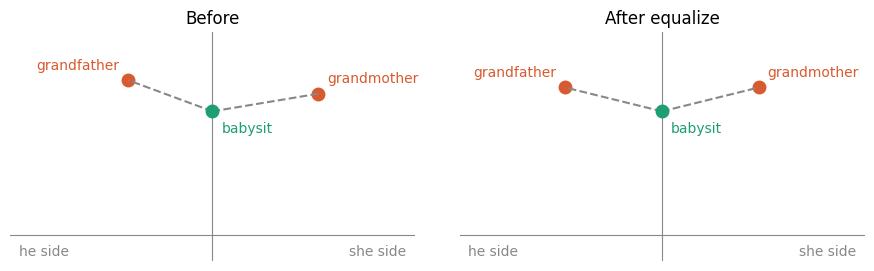

Schematic: the vertical axis squeezes the two non-gender sliders into one.


In [20]:
fig, axs = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, title in zip(axs, ["Before", "After equalize"]):
    ax.axhline(0, color="#888", lw=0.8); ax.axvline(0, color="#888", lw=0.8)
    ax.set_xlim(-1.15, 1.15); ax.set_ylim(-0.15, 1.15); ax.set_aspect("equal"); ax.axis("off"); ax.set_title(title)
    ax.text(-1.1, -0.12, "he side", color="#888"); ax.text(1.1, -0.12, "she side", ha="right", color="#888")
pts_before = [(gm[0], np.linalg.norm(gm[1:]), "grandmother"), (gf[0], np.linalg.norm(gf[1:]), "grandfather")]
pts_after  = [(gm_eq[0], np.linalg.norm(gm_eq[1:]), "grandmother"), (gf_eq[0], np.linalg.norm(gf_eq[1:]), "grandfather")]
for ax, pts in zip(axs, [pts_before, pts_after]):
    for px, py, lab in pts:
        ax.plot(px, py, "o", color="#D85A30", ms=9)
        ax.text(px + (0.05 if px > 0 else -0.05), py + 0.06, lab, color="#D85A30", ha="left" if px > 0 else "right")
        ax.plot([0, px], [0.70, py], ls="--", color="#888")
    ax.plot(0, 0.70, "o", color="#1D9E75", ms=9); ax.text(0.05, 0.58, "babysit", color="#1D9E75")
plt.tight_layout(); plt.show()
print("Schematic: the vertical axis squeezes the two non-gender sliders into one.")

**What the answer means:** After equalizing, the pair is identical except for gender, where they are mirror images. Any neutralized word sits at exactly the same distance from both. Bolukbasi et al. prove this always works (their Observation 1).

**Common mix-up:** Equalize can erase real meaning. "To grandfather a regulation" is a legitimate sense that grandmother lacks, and Equalize wipes out that difference. That tradeoff is why the paper also offers soft debiasing.

# Part 7. Bolukbasi's analogy score and δ ("delta")

**The question it answers:** Is "she is to X as he is to Y" a good analogy, and are X and Y even related?

**Everyday picture:** Scanning a dance floor for couples moving in the same direction as a reference couple. δ is the rule "only count couples who are actually dancing together," not two strangers who happen to face the same way from opposite corners.

**The formula**
$$S(x, y) = \begin{cases} \cos(\textit{she} - \textit{he},\; x - y) & \text{if } \lVert x - y \rVert \le \delta \\ 0 & \text{otherwise} \end{cases}$$
$\textit{she} - \textit{he}$ = the reference direction (here $(1,0,0)$, pure gender). $x - y$ = the direction from one candidate word to the other. $\delta$ = the "are they related?" cutoff; the paper uses $\delta = 1$.

**A shortcut you'll want:** for length-1 vectors, $\text{distance}^2 = 2 - 2 \times \text{cosine}$.

In [21]:
seed = g
def score_pair(x, y, expected_dist, expected_cos):
    sim = E[x] @ E[y]
    dist = np.sqrt(2 - 2 * sim)
    diff = E[x] - E[y]; L = np.linalg.norm(diff)
    c = (seed @ diff) / L
    print(f"Pair: she:{x} :: he:{y}")
    print(f"Distance:   √(2 − 2 × {fmt(sim)}) = √{2 - 2*sim:.2f} = {dist:.3f}     {check(dist, expected_dist, 0.001)}")
    print(f"Direction:  {x} − {y} = ({fmt(diff[0])}, {fmt(diff[1])}, {fmt(diff[2])})")
    print(f"Its length: {L:.3f}")
    print(f"Cosine with (1, 0, 0): {fmt(diff[0])} ÷ {L:.3f} = {c:.2f}     {check(c, expected_cos)}\n")
    return dist, c

d1, c1 = score_pair("nurse", "doctor", 0.849, 0.99)
d2, c2 = score_pair("babysit", "doctor", 1.414, 0.76)

print(f"{'δ':12s} {'Pair 1 (dist ' + f'{d1:.3f})':24s} {'Pair 2 (dist ' + f'{d2:.3f})':24s}")
for delta in [0.8, 1.0, 1.5]:
    r1 = f"passes → {c1:.2f}" if d1 <= delta else "fails → score 0"
    r2 = f"passes → {c2:.2f}" if d2 <= delta else "fails → score 0"
    label = f"{delta}" + (" (paper)" if delta == 1.0 else "")
    print(f"{label:12s} {r1:24s} {r2:24s}")

Pair: she:nurse :: he:doctor
Distance:   √(2 − 2 × 0.64) = √0.72 = 0.849     ✓ matches guide
Direction:  nurse − doctor = (0.84, 0.12, 0.00)
Its length: 0.849
Cosine with (1, 0, 0): 0.84 ÷ 0.849 = 0.99     ✓ matches guide

Pair: she:babysit :: he:doctor
Distance:   √(2 − 2 × 0.00) = √2.00 = 1.414     ✓ matches guide
Direction:  babysit − doctor = (1.08, 0.44, −0.80)
Its length: 1.414
Cosine with (1, 0, 0): 1.08 ÷ 1.414 = 0.76     ✓ matches guide

δ            Pair 1 (dist 0.849)      Pair 2 (dist 1.414)     
0.8          fails → score 0          fails → score 0         
1.0 (paper)  passes → 0.99            fails → score 0         
1.5          passes → 0.99            passes → 0.76           


**What the answer means:** With the paper's δ = 1, she:nurse :: he:doctor scores 0.99, a near-perfect stereotype analogy, and the unrelated babysit/doctor pair is filtered out. Change δ and the conclusions flip: at 0.8 the stereotype vanishes; at 1.5 nonsense pairs sneak in. Nissim et al.'s Table 3 makes exactly this point with the real embedding.

**Common mix-up:** δ is not something you can "get right." There is no answer key for which word pairs count as related, so δ is a judgment call that shapes the results.

# Part 8. 3CosAdd, 3CosMul, and Nissim et al.'s correction

**The question it answers:** "Man is to king as woman is to ___?" How does the computer fill in the blank, and does the code's fine print change the answer?

**Everyday picture:** A recipe swap: take chicken parmesan, remove the chicken, add eggplant. The result still tastes mostly like chicken parmesan. If you ask "which dish is closest?", the honest answer is often the original dish, unless the rules forbid it.

This part needs a different toy with four sliders: **gender, royalty, person, other senses**. *Queen* gets some "other senses" because in real text it also means a chess piece, a band, and a playing card.

In [22]:
E2 = {
    "king":   np.array([-0.28, 0.96, 0.00, 0.00]),
    "queen":  np.array([ 0.28, 0.60, 0.00, 0.75]),
    "man":    np.array([-0.28, 0.00, 0.96, 0.00]),
    "woman":  np.array([ 0.28, 0.00, 0.96, 0.00]),
    "prince": np.array([-0.30, 0.50, 0.50, 0.64]),
}
print(f"{'Word':8s} {'Gender':>7s} {'Royalty':>8s} {'Person':>7s} {'Other':>6s}")
for w, v in E2.items():
    print(f"{w:8s} " + " ".join(f"{fmt(x):>7s}" for x in v))

Word      Gender  Royalty  Person  Other
king       −0.28    0.96    0.00    0.00
queen       0.28    0.60    0.00    0.75
man        −0.28    0.00    0.96    0.00
woman       0.28    0.00    0.96    0.00
prince     −0.30    0.50    0.50    0.64


**The formula (3CosAdd)**
$$\text{answer} = \text{the word closest to } q = \textit{king} - \textit{man} + \textit{woman}$$
The computer scores every word by its dot product with $q$ ($q$ happens to have length 1 here). **Constrained** = the standard code skips king, man, and woman. **Unconstrained** = nothing is skipped.

**Step 1: build the query, then score every word**

In [23]:
q = E2["king"] - E2["man"] + E2["woman"]
print("q = king − man + woman")
print(f"  = ({fmt(q[0])}, {fmt(q[1])}, {fmt(q[2], 0) if q[2]==0 else fmt(q[2])}, {fmt(q[3], 0) if q[3]==0 else fmt(q[3])})\n")

expected_scores = {"king": 0.84, "queen": 0.65, "prince": 0.40, "woman": 0.08, "man": -0.08}
scores = {}
for w, v in E2.items():
    scores[w] = v @ q
    print(f"{w:6s} · q = ({fmt(v[0])})({fmt(q[0])}) + ({fmt(v[1])})({fmt(q[1])}) = "
          f"{sgn(v[0]*q[0])} {sgn(v[1]*q[1], lead=False)} = {fmt(scores[w])}     {check(scores[w], expected_scores[w])}")

q = king − man + woman


  = (0.28, 0.96, 0, 0)

king   · q = (−0.28)(0.28) + (0.96)(0.96) = −0.078 + 0.922 = 0.84     ✓ matches guide
queen  · q = (0.28)(0.28) + (0.60)(0.96) = 0.078 + 0.576 = 0.65     ✓ matches guide
man    · q = (−0.28)(0.28) + (0.00)(0.96) = −0.078 + 0.000 = −0.08     ✓ matches guide
woman  · q = (0.28)(0.28) + (0.00)(0.96) = 0.078 + 0.000 = 0.08     ✓ matches guide
prince · q = (−0.30)(0.28) + (0.50)(0.96) = −0.084 + 0.480 = 0.40     ✓ matches guide


In [24]:
inputs = {"king", "man", "woman"}
ranked = sorted(scores.items(), key=lambda kv: -kv[1])
constrained = [w for w, _ in ranked if w not in inputs]
print(f"{'Word':8s} {'Score':>6s}   {'Constrained (standard code)':30s} {'Unconstrained':15s}")
for i, (w, s_) in enumerate(ranked):
    c_rank = "skipped (input word)" if w in inputs else f"{constrained.index(w)+1}" + ("  ← winner" if constrained.index(w) == 0 else "")
    u_rank = f"{i+1}" + ("  ← winner" if i == 0 else "")
    print(f"{w:8s} {fmt(s_):>6s}   {c_rank:30s} {u_rank:15s}")

Word      Score   Constrained (standard code)    Unconstrained  
king       0.84   skipped (input word)           1  ← winner    
queen      0.65   1  ← winner                    2              
prince     0.40   2                              3              
woman      0.08   skipped (input word)           4              
man       −0.08   skipped (input word)           5              


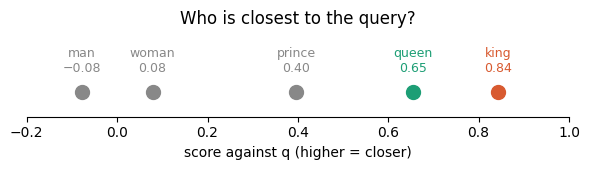

In [25]:
fig, ax = plt.subplots(figsize=(6, 1.8))
for w, s_ in scores.items():
    col = "#D85A30" if w == "king" else "#1D9E75" if w == "queen" else "#888"
    ax.plot(s_, 0, "o", color=col, ms=10); ax.text(s_, 0.04, f"{w}\n{fmt(s_)}", ha="center", color=col, fontsize=9)
ax.set_ylim(-0.05, 0.12); ax.set_xlim(-0.2, 1.0); ax.set_yticks([])
ax.set_xlabel("score against q (higher = closer)"); ax.set_title("Who is closest to the query?")
for sp in ["top", "left", "right"]: ax.spines[sp].set_visible(False)
plt.tight_layout(); plt.show()

**What the answer means:** Subtracting man and adding woman only nudges the gender slider, so the query stays parked next to *king*. The famous answer *queen* wins only because the standard code forbids returning *king*. Replace king with doctor and the same mechanism gives Nissim et al.'s headline: man is to doctor as woman is to **doctor**.

### 3CosMul: multiply instead of add
$$\text{score}(d) = \frac{\cos'(d, \textit{woman}) \times \cos'(d, \textit{king})}{\cos'(d, \textit{man}) + 0.001}, \qquad \cos' = \frac{1 + \cos}{2}$$
$\cos'$ shifts scores from the −1…1 range to 0…1, so nothing negative gets multiplied. 0.001 prevents dividing by zero.

In [26]:
cos = lambda x, y: (x @ y) / (np.linalg.norm(x) * np.linalg.norm(y))
cp = lambda x, y: (1 + cos(x, y)) / 2
def cosmul_walkthrough(d, expected):
    v = E2[d]
    a_, b_, c_ = cp(v, E2["woman"]), cp(v, E2["king"]), cp(v, E2["man"])
    print(f"{d}:  cos′({d}, woman) = (1 {'+' if cos(v,E2['woman'])>=0 else '−'} {abs(cos(v,E2['woman'])):.3f})/2 = {a_:.3f}")
    print(f"{' '*len(d)}   cos′({d}, king)  = (1 {'+' if cos(v,E2['king'])>=0 else '−'} {abs(cos(v,E2['king'])):.3f})/2 = {b_:.3f}")
    print(f"{' '*len(d)}   cos′({d}, man)   = (1 {'+' if cos(v,E2['man'])>=0 else '−'} {abs(cos(v,E2['man'])):.3f})/2 = {c_:.3f}")
    s_ = a_ * b_ / (c_ + 0.001)
    print(f"{' '*len(d)}   score = {a_:.3f} × {b_:.3f} ÷ ({c_:.3f} + 0.001) = {s_:.2f}     {check(s_, expected)}\n")
    return s_

k_score = cosmul_walkthrough("king", 0.85)
q_score = cosmul_walkthrough("queen", 0.87)

king:  cos′(king, woman) = (1 − 0.078)/2 = 0.461
       cos′(king, king)  = (1 + 1.000)/2 = 1.000
       cos′(king, man)   = (1 + 0.078)/2 = 0.539
       score = 0.461 × 1.000 ÷ (0.539 + 0.001) = 0.85     ✓ matches guide

queen:  cos′(queen, woman) = (1 + 0.078)/2 = 0.539
        cos′(queen, king)  = (1 + 0.497)/2 = 0.749
        cos′(queen, man)   = (1 − 0.078)/2 = 0.461
        score = 0.539 × 0.749 ÷ (0.461 + 0.001) = 0.87     ✓ matches guide



**What the answer means:** Under 3CosMul, queen narrowly beats king even unconstrained (0.87 vs. 0.85). Multiplying punishes king for not resembling *woman*: a weak link drags the whole product down. In the real embedding, Nissim et al. found 3CosMul also degrades without the constraint, just less than 3CosAdd (accuracy 0.73 → 0.45 vs. 0.71 → 0.21, measured on Mikolov's general analogy test set). So the method choice matters, not only the constraint.

**Common mix-up:** Nissim et al. do **not** say embeddings are unbiased. They say analogies are a poor way to measure bias, because small coding choices (the constraint, δ, vocabulary size, which queries you ask) change the answer. Projection and DirectBias (Parts 2 and 3) still show real bias.

# Part 9 (bonus). Finding the gender direction g

**The question it answers:** In a real embedding, how do we know which direction means "gender"?

**Everyday picture:** Ten people each point "north" from different spots, and their arms wobble. You want their consensus direction. If ten people point at random instead, no consensus appears.

| Step | What happens |
|---|---|
| 1 | Take pairs that differ by definition only in gender: she/he, woman/man, mother/father, and so on (10 in the paper). |
| 2 | Subtract each pair. Each difference is an arrow pointing roughly "toward female." |
| 3 | Shrink each arrow to length 1 (Tool 4). |
| 4 | Ask the computer for the single direction those arrows agree on most (PCA). It reports each direction's share of the spread. |
| 5 | If the top direction captures a big share, call it $g$. |

$$r_k = \frac{\sigma_k^2}{\sum_j \sigma_j^2} \quad \text{(share of spread on direction } k\text{)}$$

In [27]:
unit = lambda v: np.asarray(v, float) / np.linalg.norm(v)
pairs = {
    "she − he":                    unit([1.00, 0.00, 0.00]),
    "woman − man (a bit noisy)":   unit([0.95, 0.10, -0.05]),
    "grandmother − grandfather":   unit(E["grandmother"] - E["grandfather"]),
}
for name, v in pairs.items():
    print(f"{name:28s} (normalized) = ({fmt(v[0])}, {fmt(v[1])}, {fmt(v[2])})")

D = np.array(list(pairs.values()))
_, s, Vt = np.linalg.svd(D, full_matrices=False)
share = s**2 / np.sum(s**2)
g_est = Vt[0] * np.sign(Vt[0][0])
print(f"\nComputer reports: top direction explains {share[0]*100:.1f}% of the spread     {check(share[0]*100, 99.4, 0.06)}")
print(f"Estimated g ≈ ({fmt(g_est[0])}, {fmt(g_est[1])}, {fmt(g_est[2])})   ← almost exactly the gender slider")

she − he                     (normalized) = (1.00, 0.00, 0.00)
woman − man (a bit noisy)    (normalized) = (0.99, 0.10, −0.05)
grandmother − grandfather    (normalized) = (0.99, 0.04, −0.15)

Computer reports: top direction explains 99.4% of the spread     ✓ matches guide
Estimated g ≈ (1.00, 0.05, −0.07)   ← almost exactly the gender slider


**What the answer means:** In the toy, the three arrows nearly agree, so one direction explains about 99% of the spread. That percentage is a share of variance, not "how often the pairs agree." In the real embedding, words have multiple meanings ("man the station," "grandfather a regulation"), so the arrows wobble more and the top direction explains roughly 60%. That is still far above the roughly 13% you'd get from random arrows, which is the comparison in Bolukbasi et al.'s Figure 6.

# Cheat sheet

| Formula | Question it answers | 0 means… | Toy result |
|---|---|---|---|
| Cosine $u \cdot v$ | How similar are two words? | Unrelated | nurse/doctor 0.64 |
| Projection $w \cdot g$ | Which way, and how far, does a word lean? | No lean | nurse +0.36 |
| DirectBias | How much do neutral words lean on average? | Perfectly level | 0.48 (real: 0.08) |
| β | What share of a similarity comes from gender? | Gender plays no role | nurse/babysit 0.14 |
| Neutralize | Remove a neutral word's lean | (output is a new vector) | nurse → (0, 0.51, 0.86) |
| Equalize | Make a pair mirror images | (output is new vectors) | both grandparents 0.62 from babysit |
| S with δ | Is this pair a gender analogy? Are the words related? | Fails δ or no gender link | she:nurse::he:doctor 0.99 |
| 3CosAdd | Fill in the blank by vector arithmetic | Unrelated to the query | king 0.84 vs. queen 0.65 |
| 3CosMul | Same, but every relationship must hold | (scores are 0 to ~1) | queen 0.87 vs. king 0.85 |

### Three questions to ask whenever a number confuses you
1. What two things are being compared? A word and a direction, or two words?
2. What would 0 mean, and what would 1 mean?
3. Is anything removed or excluded first? (Gender stripped for β; input words skipped for 3CosAdd.)

# Experiments to try

Change one number in the toy world cell (or the four-slider table in Part 8), then re-run all cells. The ✓ checks will fail on purpose; read the new numbers instead.

1. **Make the world fair:** set the gender slider of nurse, doctor, and babysit to 0 (then fix their lengths with Tool 4). What happens to DirectBias, β, and the analogy score?
2. **Make nurse more stereotyped:** raise nurse's gender slider. Does β(nurse, doctor) get more or less negative? Why?
3. **Give queen fewer other senses:** lower queen's "other senses" from 0.75 to 0.10 (and renormalize). Does queen beat king even under 3CosAdd unconstrained?
4. **Break Equalize:** make grandmother and grandfather identical except for gender. Does Equalize change anything?
5. **Tighten δ:** in Part 7, add δ = 0.5 to the list. Which pairs survive?

# Sources

Bolukbasi, Tolga, Kai-Wei Chang, James Zou, Venkatesh Saligrama, and Adam Kalai. "Man Is to Computer Programmer as Woman Is to Homemaker? Debiasing Word Embeddings." In *Advances in Neural Information Processing Systems 29*, 4349–57. Curran Associates, 2016.

Levy, Omer, and Yoav Goldberg. "Linguistic Regularities in Sparse and Explicit Word Representations." In *Proceedings of the Eighteenth Conference on Computational Natural Language Learning*, 171–80. Association for Computational Linguistics, 2014.

Mikolov, Tomas, Wen-tau Yih, and Geoffrey Zweig. "Linguistic Regularities in Continuous Space Word Representations." In *Proceedings of the 2013 Conference of the North American Chapter of the Association for Computational Linguistics: Human Language Technologies*, 746–51. Association for Computational Linguistics, 2013.

Nissim, Malvina, Rik van Noord, and Rob van der Goot. "Fair Is Better than Sensational: Man Is to Doctor as Woman Is to Doctor." *Computational Linguistics* 46, no. 2 (2020): 487–97. https://doi.org/10.1162/coli_a_00379.